In [1]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
import random
import torch

In [2]:
# set seeds 
np.random.seed(10)
torch.manual_seed(1)
random.seed(10)

In [3]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [4]:
'''work_folder = input()
saving_folder = input()'''
work_folder = 'trivia'
saving_folder = 'prova'
os.chdir(work_folder)

In [5]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))
from Algorithms.ddpg.buffer import *

pygame 2.5.2 (SDL 2.28.2, Python 3.10.12)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [6]:
file_path = saving_folder + '/' + 'parameters.txt'  # Path to the parameters file

parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 1
Lx = 25
Ly = 25
delta = 0.3
beta = 4.5
eta = 0.0
decay_rate = 0.015
eta_special = 1
n_special = 1
t_transient = 0
tmax = 30
batch_size = 25
gamma = 0.99
max_size = 1000000
state_dim = (1, 3, 3)
action_dim = 8
action_bound = 1
actor_lr = 1e-05
critic_lr = 0.0001
tau = 0.005
noise = 0.1
weight_decay = 0.0


In [7]:
env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient)

buffer = ReplayBuffer(max_size, state_dim, action_dim)

In [8]:
action_lower_bound = 0
action_upper_bound = 1

In [9]:
from ddpg_ants import *
config_net_file = f"{saving_folder}/networks.yaml"
ddpg_ants = DDPG_ants(env, buffer, gamma, action_lower_bound, action_upper_bound, actor_lr, critic_lr, 
                                tau, batch_size, noise, weight_decay, config_net_file)

In [10]:
ddpg_ants.setup_networks()

if not os.path.exists(saving_folder + '/results'):
    os.makedirs(saving_folder + '/results')

if not os.path.exists(saving_folder + '/results_test'):
    os.makedirs(saving_folder + '/results_test')

if not os.path.exists(saving_folder + '/weights'):
    os.makedirs(saving_folder + '/weights')

with open(saving_folder + '/results/results.txt', 'w') as file:
    file.write(f"")

with open(saving_folder + '/results/reward.txt', 'w') as file:
    file.write(f"")
    
'''with open(saving_folder + '/results/op.txt', 'w') as file:
    file.write(f"")'''
    
with open(saving_folder + '/results_test/reward.txt', 'w') as file:
    file.write(f"")

'''with open(saving_folder + '/results_test/op.txt', 'w') as file:
    file.write(f"")'''

with open(saving_folder + '/results/actor_weights.txt', 'w') as file:
    file.write(f"")

with open(saving_folder + '/results/critic_weights.txt', 'w') as file:
    file.write(f"")

In [11]:
print(ddpg_ants.actor)
print(ddpg_ants.critic)

CNN_actor(
  (cnn_layers): Sequential(
    (0): Conv2d(1, 128, kernel_size=(2, 2), stride=(1, 1), padding=valid)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (dense_layers): Sequential(
    (0): Linear(in_features=512, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=8, bias=True)
    (7): Identity()
  )
)
CNN_critic(
  (cnn_layers): Sequential(
    (0): Conv2d(1, 32, kernel_size=(2, 2), stride=(1, 1), padding=valid)
    (1): ReLU()
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (action_layers): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): BatchN

In [12]:
aw = ddpg_ants.compute_actor_weights()
indx_w_actor = []

for i in range(len(aw)):
    try:
        aw[i].numpy().shape[1]
        indx_w_actor.append(i)
    except:
        pass

cw = ddpg_ants.compute_critic_weights()
indx_w_critic = []

for i in range(len(cw)):
    try:
        cw[i].numpy().shape[1]
        indx_w_critic.append(i)
    except:
        pass

In [15]:
epi = 0

In [14]:
ddpg_ants.policy(np.random.uniform(0,1,(10,1,3,3)), test=False).shape

(10, 8)

In [17]:
while epi < 50000:
        
    score, act = ddpg_ants.training_episode()

    if epi %1 == 0:
        
        if epi %10 == 0:
                
            score_test, act_test, _ = ddpg_ants.test_episode()
                
            with open(saving_folder + '/results/reward.txt', 'a') as file:
                for item in score:
                    file.write(f"{item}\n")

            with open(saving_folder + '/results_test/reward.txt', 'a') as file:
                for item in score_test:
                    file.write(f"{np.mean(item)}\n")

        aw = ddpg_ants.compute_actor_weights()
        cw = ddpg_ants.compute_critic_weights()

        with open(saving_folder + '/results/actor_weights.txt', 'a') as f:
            f.write(str([aw[i].numpy().sum() for i in indx_w_actor]) + '\n')

        with open(saving_folder + '/results/critic_weights.txt', 'a') as f:
            f.write(str([cw[i].numpy().sum() for i in indx_w_critic]) + '\n')

        ddpg_ants.save_weights(saving_folder + '/weights')

    avg_score = np.mean(score)
    avg_a = np.mean(act)
    
    with open(saving_folder + '/results/results.txt', 'a') as f:
                    
        f.write(str(epi) + ' '  + str(avg_score) + ' ' + str(avg_a) + '\n')

    epi += 1 
    
    print('epi: ', epi, ' score: ', np.sum(score), end='\r')

TypeError: DDPG_ants.get_state() missing 1 required positional argument: 'i'

In [17]:
ddpg_ants.get_state(0)[:,1,1]

array([0.02502783])

In [38]:
ddpg_ants.replay_buffer.sample(1)

(tensor([[[[0.0166, 0.0166, 0.0226],
           [0.0166, 0.0166, 0.0226],
           [0.0163, 0.0163, 0.0221]]]]),
 tensor([[1.0000e-07, 1.0000e-07, 1.2214e-02, 5.7405e-03, 1.0000e-07, 3.8619e-04,
          5.8168e-06, 1.0000e-07]]),
 tensor([[0.0226]]),
 tensor([[[[0.0166, 0.0226, 0.0301],
           [0.0166, 0.0226, 0.0301],
           [0.0163, 0.0221, 0.0295]]]]),
 tensor([[0.]]))

In [17]:
s, a, r, ns, d = ddpg_ants.replay_buffer.sample(1000)

r = 0
print(s[r], '\n', ns[r])

tensor([[[0.2980, 0.2760, 0.1768],
         [1.5222, 2.3102, 1.7832],
         [0.2144, 0.1294, 0.1753]]]) 
 tensor([[[0.2719, 0.1742, 0.1215],
         [3.6256, 1.7567, 0.1850],
         [0.1275, 0.1727, 0.2317]]])


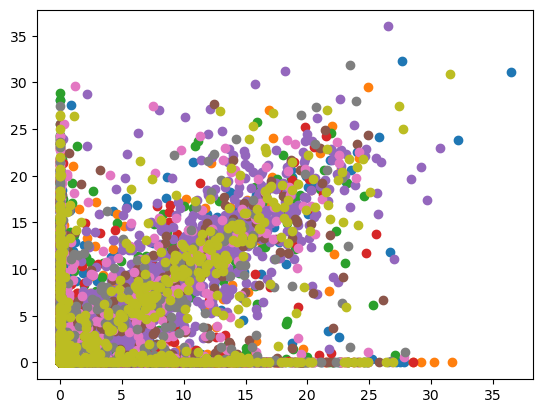

In [14]:
plt.plot(s[:,0].reshape(1000,9), ns[:,0].reshape(1000,9), 'o')